Generating Exploratory Data Analysis (EDA) plots...


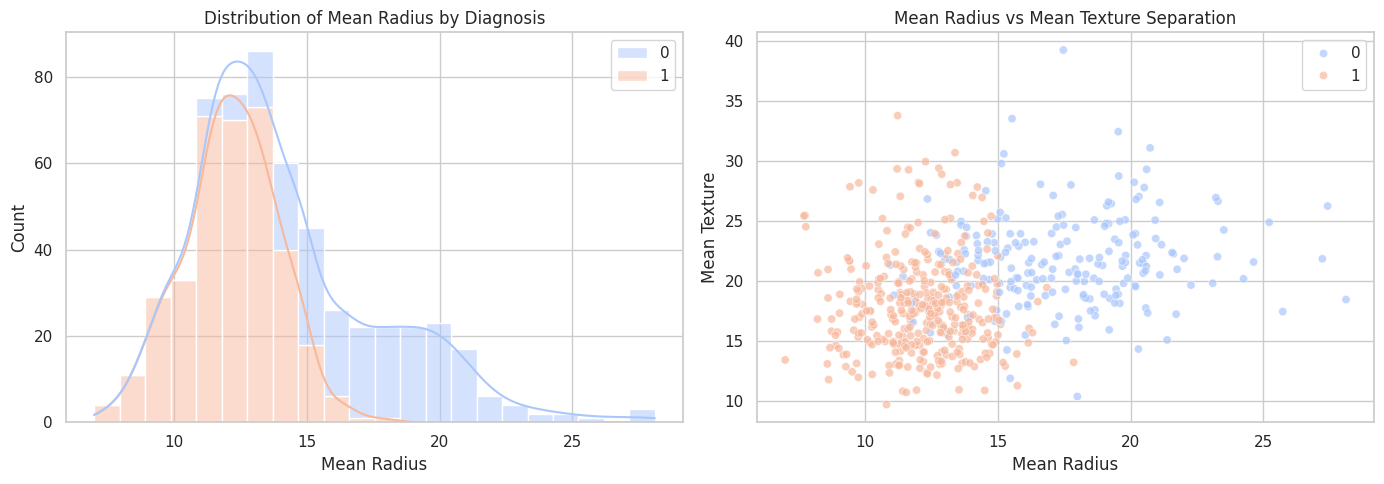

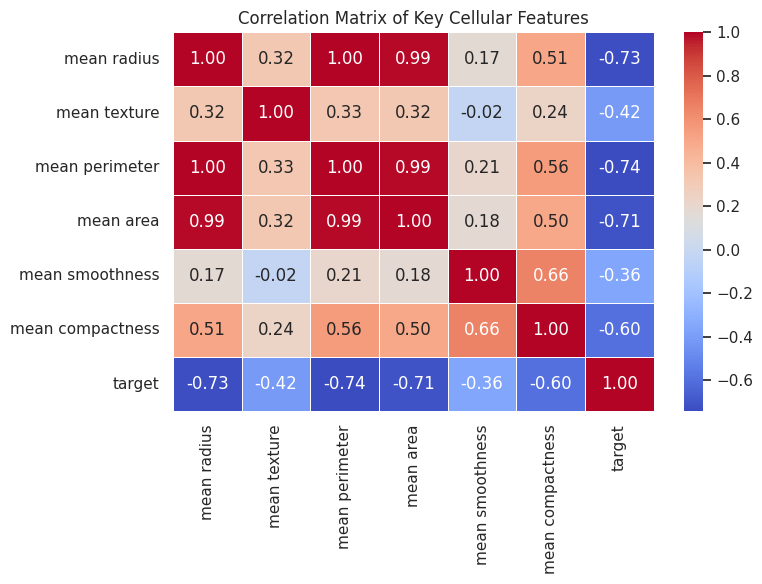


Training the Deep Feed-Forward Network...
Epoch 1/40


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 67ms/step - accuracy: 0.6601 - loss: 0.6327 - val_accuracy: 0.7609 - val_loss: 0.4878
Epoch 2/40
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.8606 - loss: 0.4413 - val_accuracy: 0.8696 - val_loss: 0.3381
Epoch 3/40
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.9071 - loss: 0.3236 - val_accuracy: 0.8913 - val_loss: 0.2538
Epoch 4/40
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9340 - loss: 0.2606 - val_accuracy: 0.9130 - val_loss: 0.2028
Epoch 5/40
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9462 - loss: 0.2074 - val_accuracy: 0.9130 - val_loss: 0.1730
Epoch 6/40
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9487 - loss: 0.1749 - val_accuracy: 0.9348 - val_loss: 0.1522
Epoch 7/40
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9560 - loss: 0.1493 - val_accuracy: 0.9348 - val_loss: 0.1379
Epoch 8/40
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9633 - loss: 0.1408 - val_accuracy: 0.9348 - val_loss: 0.

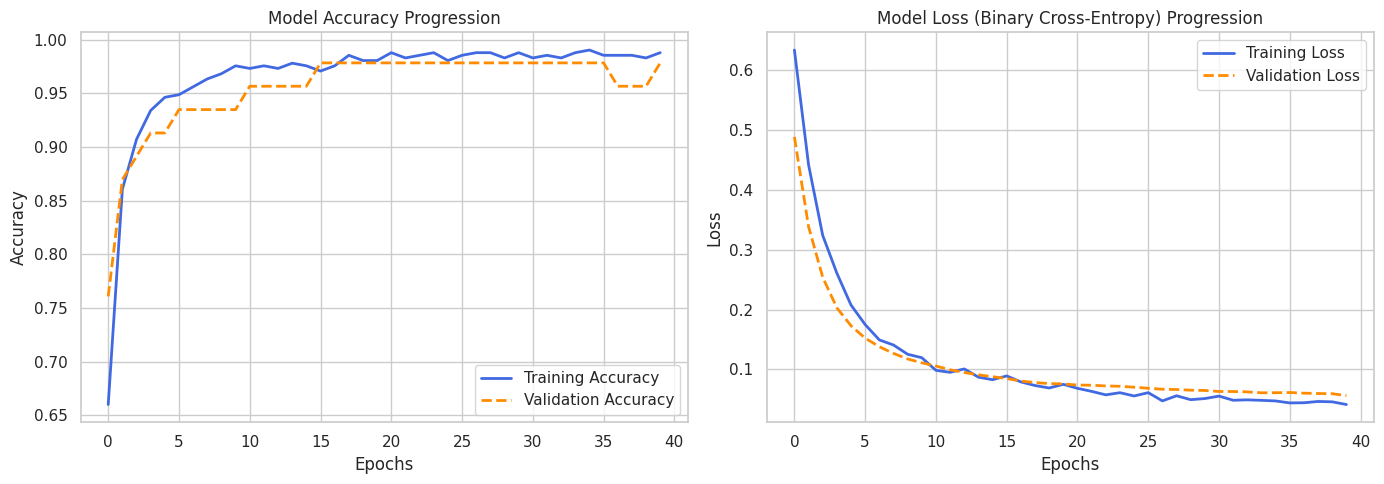

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step

Final Testing Diagnostic Accuracy: 97.37%


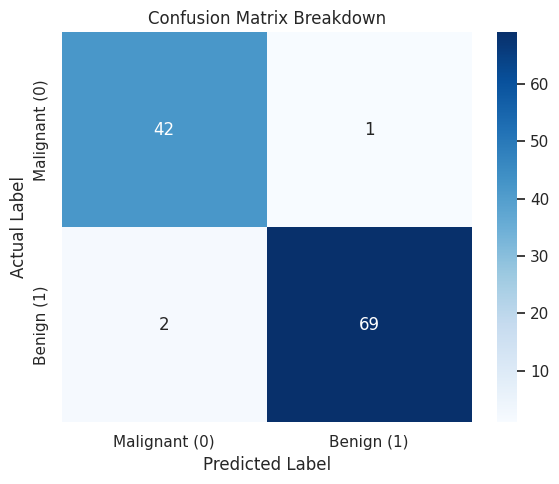

In [1]:
#Jivesh_Chawla_23070521041
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from sklearn.metrics import confusion_matrix, accuracy_score

# Set style for aesthetic visualizations
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 5)

# =============================================================
# 1. LOAD THE DATASET
# =============================================================
cancer_data = load_breast_cancer()
X = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)
y = cancer_data.target  # 0 = Malignant, 1 = Benign

# =============================================================
# 2. EXPLORATORY DATA VISUALIZATION (BEFORE TRAINING)
# =============================================================
print("Generating Exploratory Data Analysis (EDA) plots...")

# Plot A: Feature Distributions & Separation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=X, x=X['mean radius'], hue=y, kde=True, multiple='stack', ax=axes[0], palette='coolwarm')
axes[0].set_title('Distribution of Mean Radius by Diagnosis')
axes[0].set_xlabel('Mean Radius')

sns.scatterplot(data=X, x=X['mean radius'], y=X['mean texture'], hue=y, alpha=0.7, ax=axes[1], palette='coolwarm')
axes[1].set_title('Mean Radius vs Mean Texture Separation')
axes[1].set_xlabel('Mean Radius')
axes[1].set_ylabel('Mean Texture')
plt.tight_layout()
plt.show()

# Plot B: Feature Correlation Heatmap (Top 6 highly varying features)
plt.figure(figsize=(8, 6))
selected_features = ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness']
correlation_matrix = X[selected_features].copy()
correlation_matrix['target'] = y
sns.heatmap(correlation_matrix.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Key Cellular Features')
plt.tight_layout()
plt.show()

# =============================================================
# 3. DATA PREPROCESSING
# =============================================================
# Split into 80% Training and 20% Testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardizing features (Z-score normalization)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# =============================================================
# 4. DEEP NEURAL NETWORK ARCHITECTURE
# =============================================================
model = Sequential()

# Input layer + First Hidden layer
model.add(Dense(units=32, activation='relu', input_shape=(X_train.shape[1],)))
model.add(Dropout(0.2)) # Prevents overfitting

# Second Hidden layer
model.add(Dense(units=16, activation='relu'))

# Output layer (Sigmoid outputs value between 0 and 1)
model.add(Dense(units=1, activation='sigmoid'))

# Compile Model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# =============================================================
# 5. MODEL TRAINING
# =============================================================
print("\nTraining the Deep Feed-Forward Network...")
history = model.fit(
    X_train, y_train,
    epochs=40,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

# =============================================================
# 6. PERFORMANCE VISUALIZATION (POST-TRAINING)
# =============================================================
print("\nGenerating Post-Training Performance evaluation...")

# Plot C: Learning Curves (Loss and Accuracy updates over Epochs)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy Curve
axes[0].plot(history.history['accuracy'], label='Training Accuracy', linewidth=2, color='royalblue')
axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2, linestyle='--', color='darkorange')
axes[0].set_title('Model Accuracy Progression')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

# Loss Curve
axes[1].plot(history.history['loss'], label='Training Loss', linewidth=2, color='royalblue')
axes[1].plot(history.history['val_loss'], label='Validation Loss', linewidth=2, linestyle='--', color='darkorange')
axes[1].set_title('Model Loss (Binary Cross-Entropy) Progression')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Loss')
axes[1].legend()

plt.tight_layout()
plt.show()

# =============================================================
# 7. CONFUSION MATRIX VISUALIZATION
# =============================================================
# Compute predictions
y_pred_prob = model.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int)

acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print(f"\nFinal Testing Diagnostic Accuracy: {acc * 100:.2f}%")

# Plot D: Confusion Matrix Heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Malignant (0)', 'Benign (1)'],
            yticklabels=['Malignant (0)', 'Benign (1)'])
plt.title('Confusion Matrix Breakdown')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.show()